# 1. Load dataset and preprocessing

Đọc dữ liệu, chia training/validation và chuẩn hóa ảnh.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import transforms
from torch.utils.data import DataLoader
from sklearn.preprocessing import LabelEncoder

from pathlib import Path
import sys

# Dùng chung hàm đọc FER2013, Dataset và cách chia tập với thí nghiệm Baseline.
project = next(p for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "BTL02")
               if (p / "fer_data.py").is_file())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
from fer_data import EMOTIONS, EmotionDataset, load_images, split_train_valid

train_df = pd.read_csv(project / "data/train.csv")
test_df = pd.read_csv(project / "data/test.csv")
train_indices, valid_indices = split_train_valid(train_df)
x_train = load_images(train_df.iloc[train_indices].reset_index(drop=True))
x_valid = load_images(train_df.iloc[valid_indices].reset_index(drop=True))
x_test = load_images(test_df)
y_train = train_df.iloc[train_indices]["emotion"].to_numpy()
y_valid = train_df.iloc[valid_indices]["emotion"].to_numpy()

label_encoder = LabelEncoder()
label_encoder.fit(train_df["emotion"])
y_train_indices = label_encoder.transform(y_train)
y_valid_indices = label_encoder.transform(y_valid)
y_train = np.eye(len(label_encoder.classes_), dtype=np.float32)[label_encoder.transform(y_train)]
y_valid = np.eye(len(label_encoder.classes_), dtype=np.float32)[label_encoder.transform(y_valid)]

# Normalize in place to avoid extra float32 copies.
x_train = x_train.astype("float32", copy=False)
x_valid = x_valid.astype("float32", copy=False)
x_test = x_test.astype("float32", copy=False)
x_train /= 255.0
x_valid /= 255.0
x_test /= 255.0

print("Classes:", label_encoder.classes_)
print("x_train:", x_train.shape, "y_train:", y_train.shape)
print("x_valid:", x_valid.shape, "y_valid:", y_valid.shape)
print("x_test:", x_test.shape)
print("Pixel range:", x_train.min(), x_train.max())


Classes: [0 1 2 3 4 5 6]
x_train: (22967, 48, 48, 1) y_train: (22967, 7)
x_valid: (5742, 48, 48, 1) y_valid: (5742, 7)
x_test: (7178, 48, 48, 1)
Pixel range: 0.0 1.0


# 2. Data augmentation

Chỉ áp dụng các phép biến đổi ngẫu nhiên cho tập training. Tập validation và testing giữ nguyên để đánh giá công bằng.


In [2]:
train_transform = transforms.Compose([
    transforms.RandomRotation(30),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.RandomHorizontalFlip(p=0.5),
])

train_dataset = EmotionDataset(x_train, y_train_indices, transform=train_transform)
valid_dataset = EmotionDataset(x_valid, y_valid_indices)
test_dataset = EmotionDataset(x_test)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("Training images:", len(train_dataset), "- shape:", tuple(train_dataset[0][0].shape))
print("Validating images:", len(valid_dataset), "- shape:", tuple(valid_dataset[0][0].shape))
print("Testing images:", len(test_dataset), "- shape:", tuple(test_dataset[0].shape))


Training images: 22967 - shape: (1, 48, 48)
Validating images: 5742 - shape: (1, 48, 48)
Testing images: 7178 - shape: (1, 48, 48)


# 3. Phân phối nhãn

Kiểm tra số lượng mẫu của từng emotion trong tập training và validation.



Số lượng từng emotion:


,Training,Validation
emotion,,
0,3196,799
1,349,87
2,3277,820
3,5772,1443
4,3864,966
5,2537,634
6,3972,993


Testing không có cột emotion nên không thể đếm nhãn theo emotion.
Tổng số ảnh testing: 7178


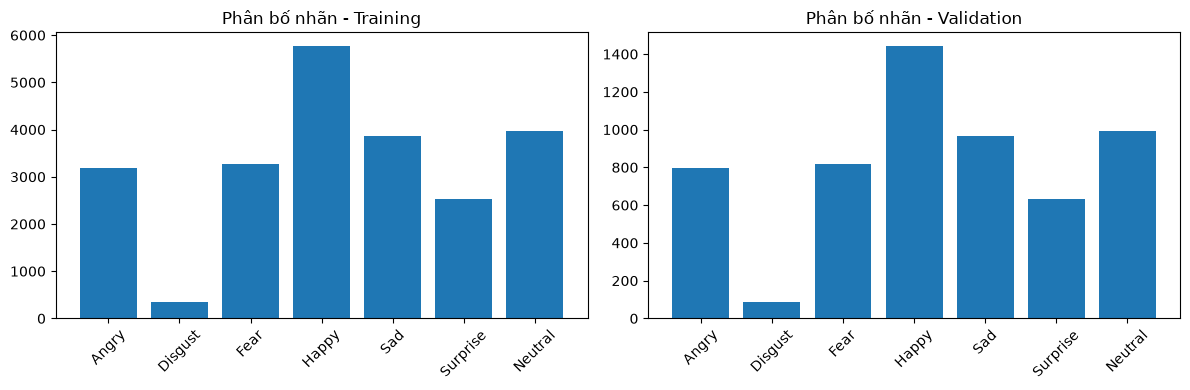

In [3]:
emotion_values = label_encoder.classes_
train_emotion_counts = train_df.iloc[train_indices]["emotion"].value_counts().reindex(
    emotion_values, fill_value=0
)
valid_emotion_counts = train_df.iloc[valid_indices]["emotion"].value_counts().reindex(
    emotion_values, fill_value=0
)
emotion_counts = pd.DataFrame({
    "Training": train_emotion_counts,
    "Validation": valid_emotion_counts,
})
print("\nSố lượng từng emotion:")
display(emotion_counts)

if "emotion" in test_df.columns:
    test_emotion_counts = test_df["emotion"].value_counts().reindex(
        emotion_values, fill_value=0
    )
    emotion_counts["Testing"] = test_emotion_counts
else:
    print("Testing không có cột emotion nên không thể đếm nhãn theo emotion.")
    print("Tổng số ảnh testing:", len(test_df))

emotion_names = list(EMOTIONS)
train_counts = np.bincount(y_train_indices, minlength=len(emotion_names))
valid_counts = np.bincount(y_valid_indices, minlength=len(emotion_names))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(emotion_names, train_counts)
axes[0].set_title("Phân bố nhãn - Training")
axes[0].tick_params(axis="x", rotation=45)
axes[1].bar(emotion_names, valid_counts)
axes[1].set_title("Phân bố nhãn - Validation")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


# 4. Phân phối pixel

Trực quan hóa phân phối giá trị pixel đã chuẩn hóa.


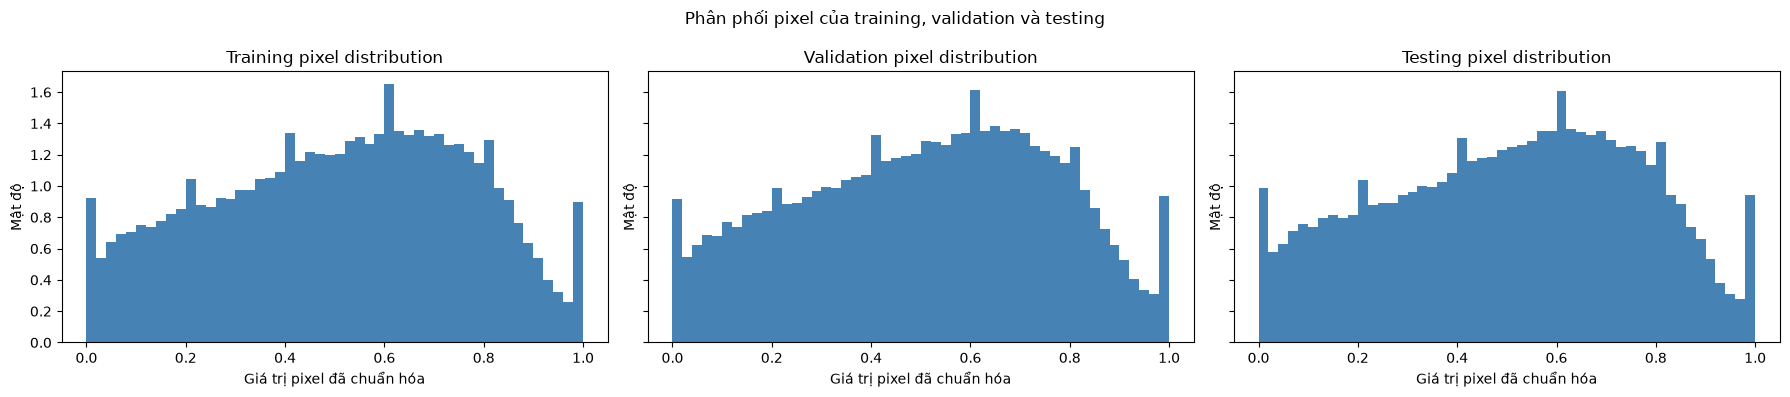

In [4]:
rng = np.random.default_rng(42)
train_hist = rng.choice(x_train.reshape(-1), 100_000, replace=False)
valid_hist = rng.choice(x_valid.reshape(-1), 100_000, replace=False)
test_hist = rng.choice(x_test.reshape(-1), 100_000, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, values, title in zip(
    axes,
    (train_hist, valid_hist, test_hist),
    ("Training", "Validation", "Testing"),
):
    ax.hist(values, bins=50, range=(0, 1), density=True, color="steelblue")
    ax.set_title(f"{title} pixel distribution")
    ax.set_xlabel("Giá trị pixel đã chuẩn hóa")
    ax.set_ylabel("Mật độ")
fig.suptitle("Phân phối pixel của training, validation và testing")
plt.tight_layout()
plt.show()


# 5. Ảnh mẫu

Hiển thị một số ảnh mẫu từ tập training, validation và testing.


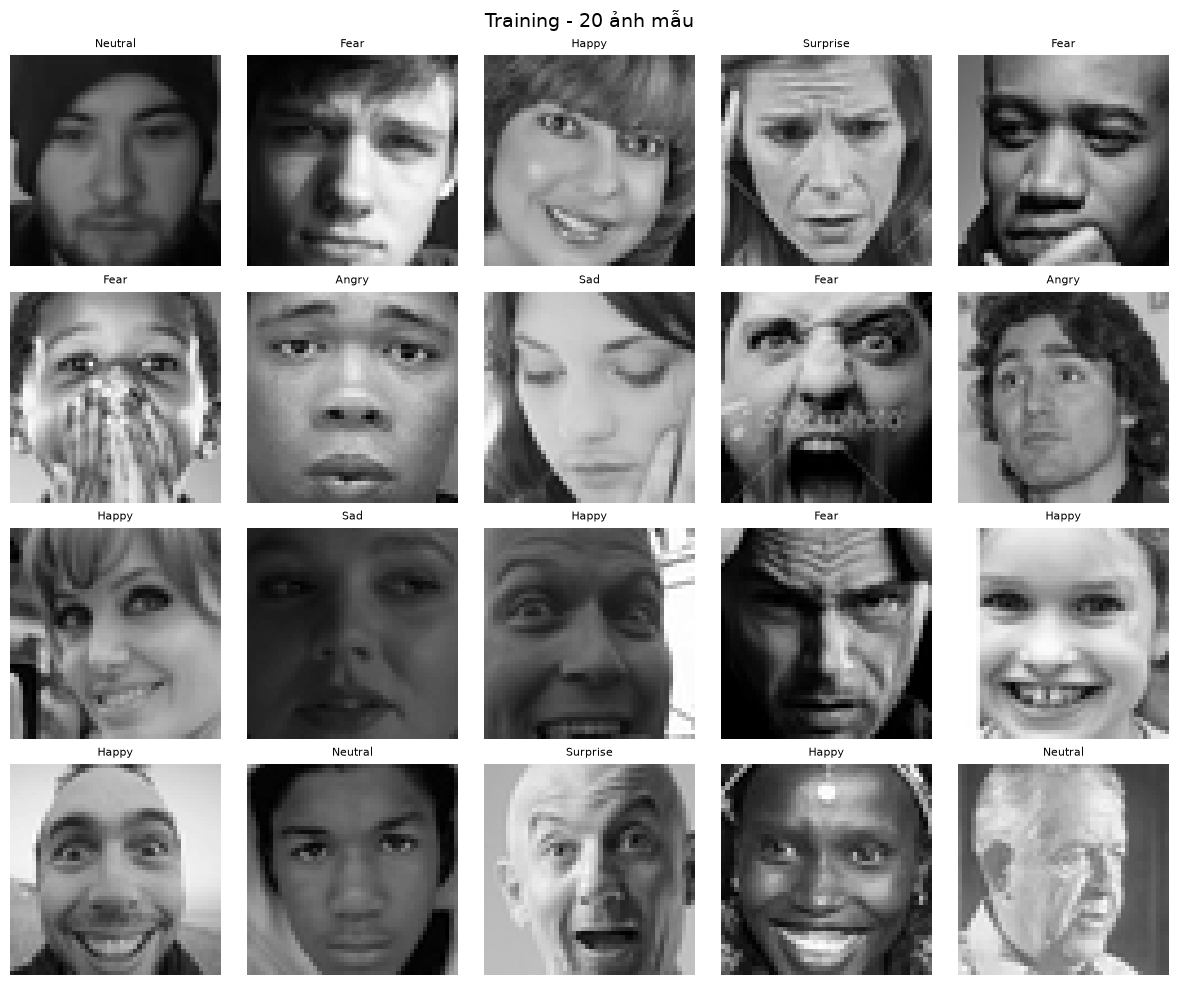

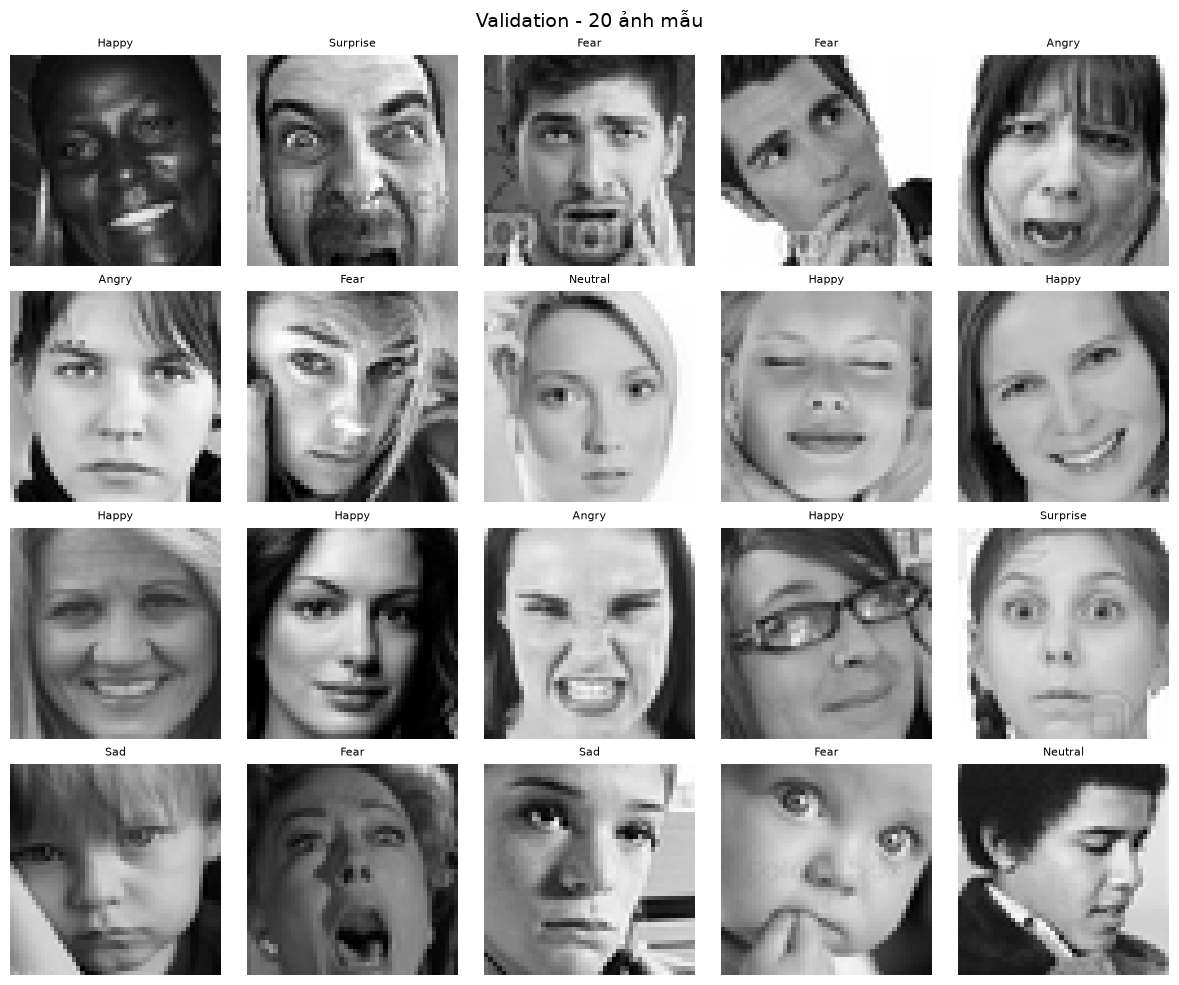

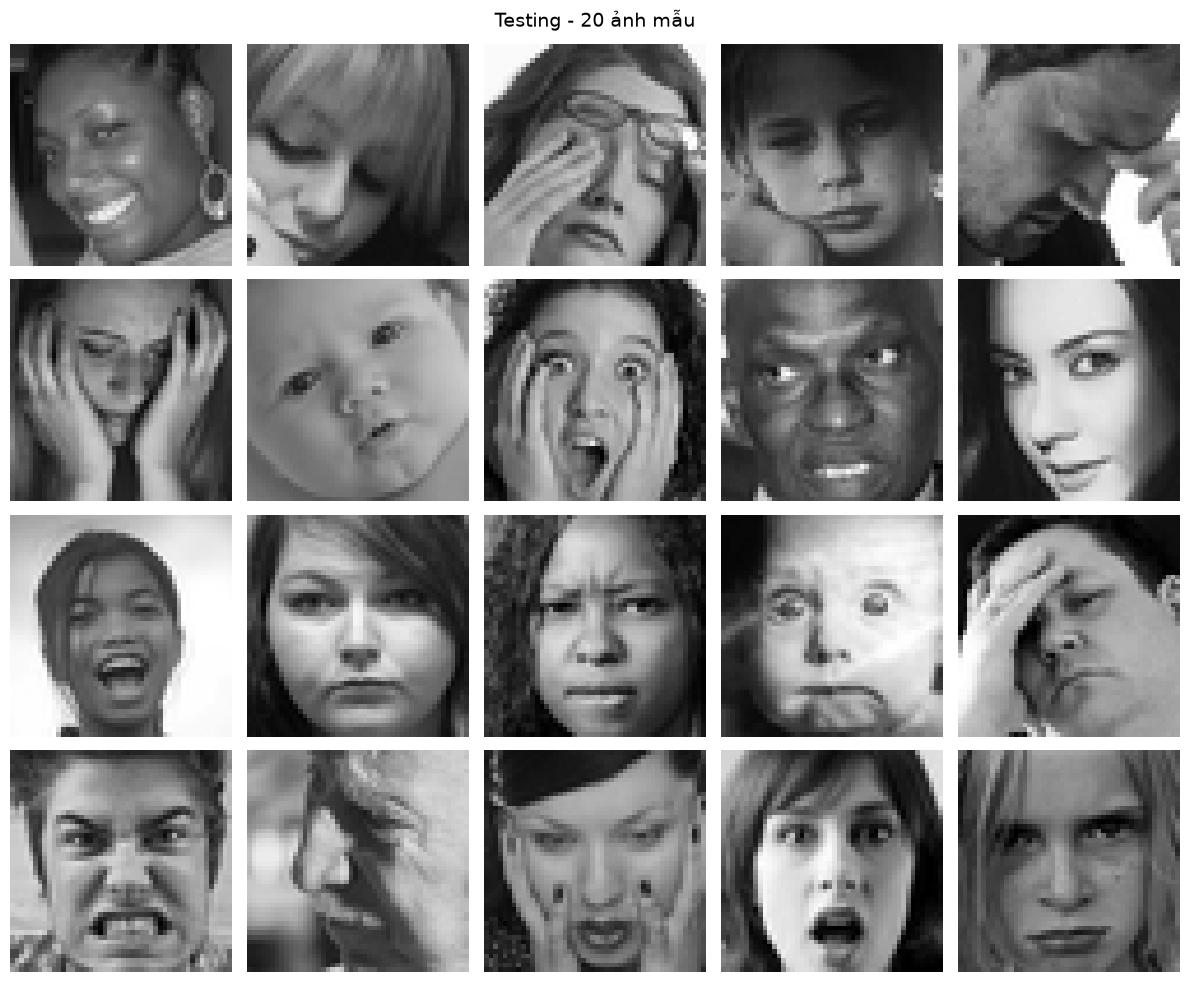

In [5]:
def show_samples(images, labels, title, sample_count=20):
    indices = rng.choice(len(images), sample_count, replace=False)
    fig, axes = plt.subplots(4, 5, figsize=(12, 10))
    for ax, index in zip(axes.flat, indices):
        ax.imshow(images[index].squeeze(), cmap="gray", vmin=0, vmax=1)
        if labels is not None:
            ax.set_title(emotion_names[labels[index]], fontsize=8)
        ax.axis("off")
    fig.suptitle(f"{title} - 20 ảnh mẫu", fontsize=14)
    plt.tight_layout()
    plt.show()

show_samples(x_train, y_train_indices, "Training")
show_samples(x_valid, y_valid_indices, "Validation")
show_samples(x_test, None, "Testing")
